# 06 — Head Localization: Learned Sparse Mask

Learn a continuous mask over `(n_layers_tested, n_heads)` attention heads that selects the minimal set whose cross-language interchange (C++ source → Python destination) minimizes `KL(P_patched ∥ P_target)`.

**Objective:**
```
L = KL(P_patched ∥ P_target) + λ * Σ mask
```
- `P_patched`: next-token dist of dest prompt with mask-weighted head patch from source (C++)
- `P_target`: next-token dist of Python target prompt (same predicate as C++ source)
- Mask: `(n_layers_tested, n_heads)` values ∈ [0,1], initialized to 1, projected GD (no sigmoid)
- Selection: heads where mask > 0.5 after training

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import logging
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
# os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
##################################################################

logging.basicConfig(
    level=logging.DEBUG,
    format="%(asctime)s %(levelname)s %(name)s — %(message)s",
    datefmt="%H:%M:%S",
)

MODEL_KEY = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_KEY = "Qwen/Qwen2.5-Coder-32B-Instruct"

print(f"torch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")

torch: 2.10.0+cu128, CUDA: True


## Model init

In [3]:
from src.models import ModelandTokenizer

mt = ModelandTokenizer(
    model_key=MODEL_KEY,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

17:10:08 WARNING src.models — Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
17:10:08 DEBUG httpcore.connection — connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
17:10:08 DEBUG httpcore.connection — connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7feb60e3a300>
17:10:08 DEBUG httpcore.connection — start_tls.started ssl_context=<ssl.SSLContext object at 0x7feb607bac50> server_hostname='huggingface.co' timeout=10
17:10:08 DEBUG httpcore.connection — start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7feb60c16330>
17:10:08 DEBUG httpcore.http11 — send_request_headers.started request=<Request [b'HEAD']>
17:10:08 DEBUG httpcore.http11 — send_request_headers.complete
17:10:08 DEBUG httpcore.http11 — send_request_body.started request=<Request [b'HEAD']>
17:10:08 DEBUG http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

17:10:28 DEBUG httpcore.connection — close.started
17:10:28 DEBUG httpcore.connection — close.complete
17:10:28 DEBUG httpcore.connection — connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
17:10:28 DEBUG httpcore.connection — connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7feb60dc33b0>
17:10:28 DEBUG httpcore.connection — start_tls.started ssl_context=<ssl.SSLContext object at 0x7feb607bac50> server_hostname='huggingface.co' timeout=10
17:10:28 DEBUG httpcore.connection — start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7feb603dade0>
17:10:28 DEBUG httpcore.http11 — send_request_headers.started request=<Request [b'HEAD']>
17:10:28 DEBUG httpcore.http11 — send_request_headers.complete
17:10:28 DEBUG httpcore.http11 — send_request_body.started request=<Request [b'HEAD']>
17:10:28 DEBUG httpcore.http11 — send_request_body.complete
17:10:28 DEBUG httpcore.http11 — receive_r

n_layer=64, n_embd=5120, n_heads=40
head_dim=128
attn_module_name_format='model.layers.{}.self_attn'


## Load data

In [4]:
from src.goals.head_loc_data import HeadLocDataset

ds = HeadLocDataset.load()
pivot_instances = HeadLocDataset.load_pivot_instances()

print(f"Dataset: {len(ds)} samples, {len(ds.pairs)} pairs")
print(f"Pivot instances: {len(pivot_instances)}")

17:10:29 INFO src.goals.head_loc_data — Loaded 6 predicates, 6 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc


Dataset: 6 samples, 6 pairs
Pivot instances: 10


## Inspect a pivot instance

In [5]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

pi = pivot_instances[0]
print(f"PivotInstance:")
print(f"  source_predicate  : {pi.source_predicate}")
print(f"  destination_pred  : {pi.destination_predicate}")
print(f"  target_predicate  : {pi.target_predicate}")
print(f"  pivot_prefix      : {pi.pivot_prefix!r}")
print(f"  dest_top_token    : {pi.dest_top_token!r}")
print(f"  target_top_token  : {pi.target_top_token!r}")
print(f"  tokens_diverge    : {pi.tokens_diverge}")

src_sample  = ds.get_sample(pi.source_predicate)
dest_sample = ds.get_sample(pi.destination_predicate)
targ_sample = ds.get_sample(pi.target_predicate)

print("\n--- Source (C++) prompt ---")
print(build_cpp_prompt(mt, src_sample))

print("\n--- Dest (Python) prompt ---")
print(build_python_prompt(mt, dest_sample, pivot_prefix=pi.pivot_prefix))

print("\n--- Target (Python) prompt ---")
print(build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix))

PivotInstance:
  source_predicate  : has_duplicates
  destination_pred  : is_sorted
  target_predicate  : has_duplicates
  pivot_prefix      : ''
  dest_top_token    : ' all'
  target_top_token  : ' len'
  tokens_diverge    : True

--- Source (C++) prompt ---
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
bool hasDuplicates(vector<int> lst) { return 

--- Dest (Python) prompt ---
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_sorted(lst: list[int]) -> bool:
    return 

--- Tar

## Cache pivot data (one-time, ~2 forward passes per instance)

In [6]:
from src.goals.head_loc_attn import cache_pivot_data

LAYERS = list(range(20, 60))

pivot_caches = cache_pivot_data(mt, pivot_instances, ds, layers=LAYERS)

print(f"Cached {len(pivot_caches)} instances")
c = pivot_caches[0]
print(f"per_head_deltas shape: {c.per_head_deltas.shape}")  # (n_layers, n_heads, n_embd)
print(f"log_p_target shape:    {c.log_p_target.shape}")

17:10:29 INFO src.goals.head_loc_attn —   Caching 1/10: is_sorted ← has_duplicates prefix=''
17:10:46 INFO src.goals.head_loc_attn —   Caching 2/10: has_duplicates ← is_sorted prefix=''
17:11:02 INFO src.goals.head_loc_attn —   Caching 3/10: is_power_of_two ← is_odd prefix=''
17:11:18 INFO src.goals.head_loc_attn —   Caching 4/10: is_odd ← is_power_of_two prefix=''
17:11:34 INFO src.goals.head_loc_attn —   Caching 5/10: is_upper ← is_palindrome prefix=''
17:11:50 INFO src.goals.head_loc_attn —   Caching 6/10: is_palindrome ← is_upper prefix=''
17:12:06 INFO src.goals.head_loc_attn —   Caching 7/10: is_power_of_two ← is_odd prefix='0'
17:12:22 INFO src.goals.head_loc_attn —   Caching 8/10: is_odd ← is_power_of_two prefix='0'
17:12:38 INFO src.goals.head_loc_attn —   Caching 9/10: is_upper ← is_palindrome prefix=' s'
17:12:54 INFO src.goals.head_loc_attn —   Caching 10/10: is_palindrome ← is_upper prefix=' s'
17:13:10 INFO src.goals.head_loc_attn — cache_pivot_data: cached 10 pivot insta

Cached 10 instances
per_head_deltas shape: torch.Size([40, 40, 5120])
log_p_target shape:    torch.Size([152064])


In [7]:
c

PivotCache(pivot_instance=PivotInstance(source_predicate='has_duplicates', destination_predicate='is_sorted', target_predicate='has_duplicates', pivot_prefix='', dest_top_token=' all', target_top_token=' len'), dest_inputs={'input_ids': tensor([[151644,   8948,    198,   2610,    525,    264,  10950,  17847,  68265,
            304,  15473,     13,   3197,  26568,   2038,     11,   5978,   6169,
          19482,    323,  19819,  57323,     13,   7405,   2704,    311,    614,
            678,  13912,   4766,    279,    366,   1851,     29,    690,   1851,
             29,   9492,     13, 151645,    198, 151644,    872,    198,  12548,
            279,  13027,    729,   3685,     13, 151645,    198, 151644,  77091,
            198,     27,   1851,    397,    750,    374,  41277,  46046,     25,
           1140,  18640,   2467,   1464,   1807,    510,    262,    470,    220]],
       device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

In [8]:
mt.attn_module_name_format

'model.layers.{}.self_attn'

## Train the head mask

In [18]:
from src.goals.head_loc_attn import train_head_mask

mask, history = train_head_mask(
    mt,
    pivot_caches,
    layers=LAYERS,
    n_epochs=25,
    lr=1e-2,
    lambda_sparse=2e-2,
)

n_heads = mt.model.config.num_attention_heads
print(f"\nFinal active heads: {mask.n_active()} / {len(LAYERS) * n_heads}")
print("Selected:", mask.selected_heads(LAYERS))

17:25:30 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 25 epochs | lr=0.01 λ=0.02


17:25:32 INFO src.goals.head_loc_attn —   Epoch   1/25: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:25:42 INFO src.goals.head_loc_attn —   Epoch   5/25: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:25:53 INFO src.goals.head_loc_attn —   Epoch  10/25: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:26:05 INFO src.goals.head_loc_attn —   Epoch  15/25: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:26:17 INFO src.goals.head_loc_attn —   Epoch  20/25: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:26:30 INFO src.goals.head_loc_attn —   Epoch  25/25: KL=1.6459  sparse=2.3777  total=4.0236  n_active=102
17:26:30 INFO src.goals.head_loc_attn — train_head_mask done: 102 active heads → [(27, 10), (29, 1), (30, 8), (30, 23), (30, 35), (31, 16), (31, 18), (31, 19), (31, 32), (31, 34), (33, 34), (34, 22), (35, 13), (35, 39), (38, 0), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (40, 3), (40, 8), (40, 32), (40, 34), (41, 9), (41, 12), (42, 


Final active heads: 102 / 1600
Selected: [(27, 10), (29, 1), (30, 8), (30, 23), (30, 35), (31, 16), (31, 18), (31, 19), (31, 32), (31, 34), (33, 34), (34, 22), (35, 13), (35, 39), (38, 0), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (40, 3), (40, 8), (40, 32), (40, 34), (41, 9), (41, 12), (42, 11), (43, 5), (43, 14), (43, 15), (44, 21), (45, 1), (45, 3), (45, 15), (45, 17), (45, 18), (45, 24), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 37), (46, 39), (47, 8), (47, 17), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (48, 39), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16), (49, 24), (49, 29), (49, 35), (49, 36), (50, 0), (50, 15), (50, 17), (51, 2), (51, 4), (51, 16), (51, 17), (51, 35), (51, 36), (52, 1), (52, 3), (53, 5), (53, 6), (53, 8), (53, 20), (53, 24), (54, 11), (54, 17), (55, 18), (55, 19), (55, 20), (55, 21), (55, 23), (55, 32), (55, 37), (56, 0), (56, 16), (56, 19), (58, 10), (58, 11), (59, 1), (59,

## Training curves

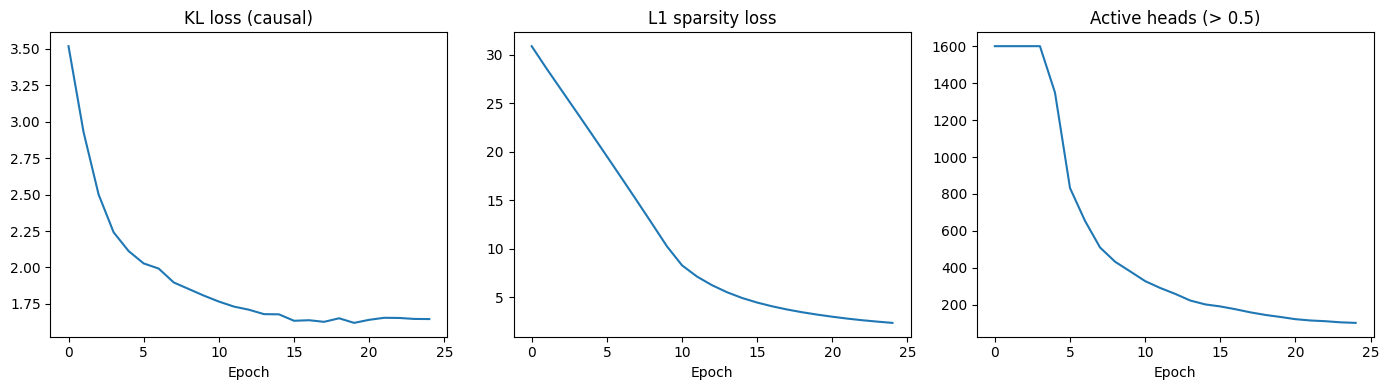

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history.loss_causal)
axes[0].set_title("KL loss (causal)")
axes[0].set_xlabel("Epoch")

axes[1].plot(history.loss_sparse)
axes[1].set_title("L1 sparsity loss")
axes[1].set_xlabel("Epoch")

axes[2].plot(history.n_active)
axes[2].set_title("Active heads (> 0.5)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## Mask heatmap

17:26:50 DEBUG matplotlib.colorbar — locator: <matplotlib.ticker.AutoLocator object at 0x7feb561985f0>


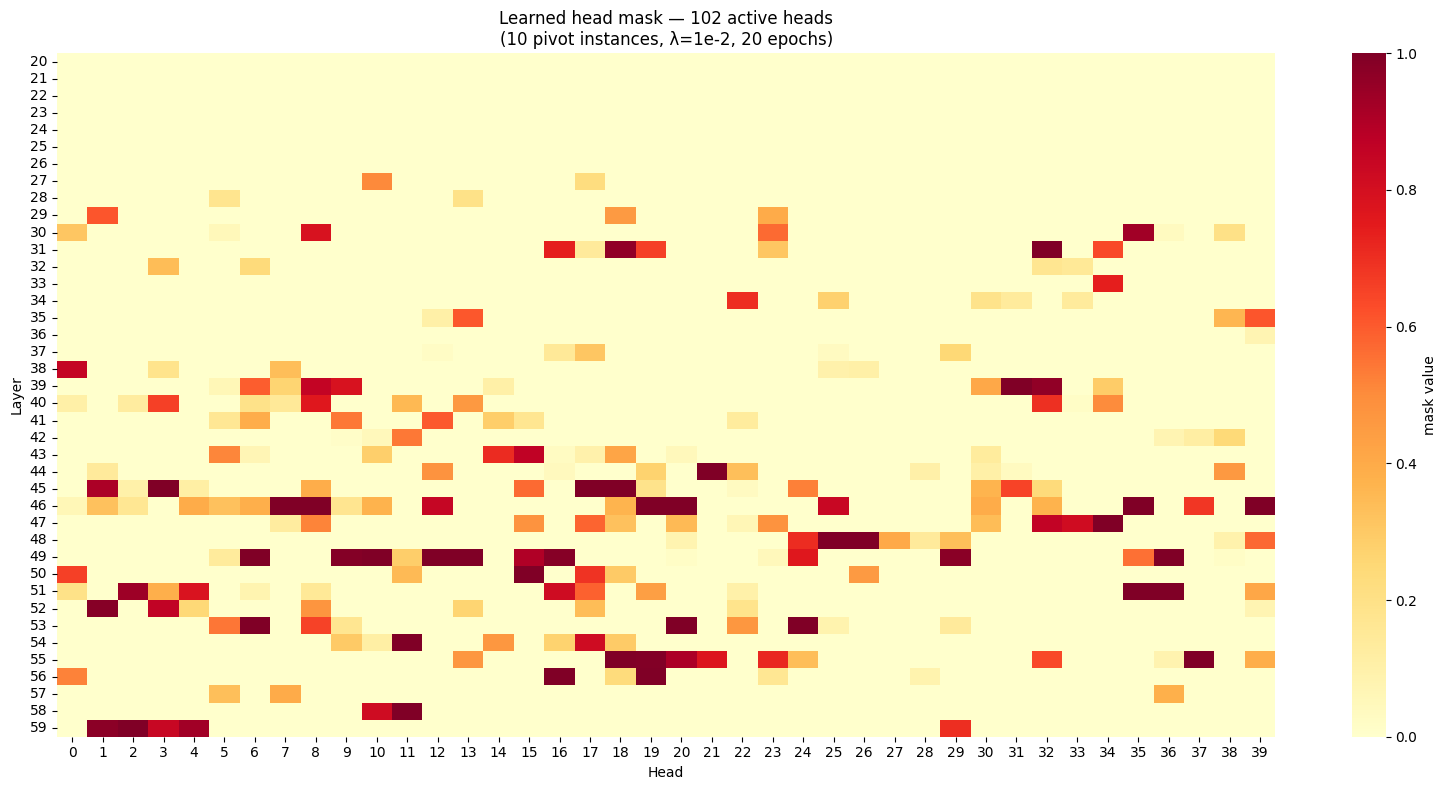


Top 10 heads by mask value:
  layer=54 head=11: 1.0000
  layer=31 head=32: 1.0000
  layer=59 head=2: 1.0000
  layer=45 head=3: 1.0000
  layer=45 head=17: 1.0000
  layer=45 head=18: 1.0000
  layer=49 head=12: 1.0000
  layer=51 head=36: 1.0000
  layer=46 head=7: 1.0000
  layer=46 head=8: 1.0000


In [20]:
mask_vals = mask.values.detach().cpu().numpy()  # (n_layers_tested, n_heads)

fig, ax = plt.subplots(figsize=(16, 8))
sns.heatmap(
    mask_vals, ax=ax, cmap="YlOrRd", vmin=0, vmax=1,
    xticklabels=range(n_heads),
    yticklabels=[str(l) for l in LAYERS],
    cbar_kws={"label": "mask value"},
)
ax.set_title(
    f"Learned head mask — {mask.n_active()} active heads\n"
    f"({len(pivot_instances)} pivot instances, λ=1e-2, 20 epochs)"
)
ax.set_xlabel("Head")
ax.set_ylabel("Layer")
plt.tight_layout()
plt.show()

print("\nTop 10 heads by mask value:")
flat = mask_vals.flatten()
for idx in np.argsort(flat)[::-1][:10]:
    li, h = divmod(int(idx), n_heads)
    print(f"  layer={LAYERS[li]} head={h}: {mask_vals[li, h]:.4f}")

## Sparsity sweep: λ vs. n_active vs. KL (Pareto frontier)

17:14:02 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 20 epochs | lr=0.01 λ=0.001
17:14:04 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.6388  sparse=1.5710  total=5.2098  n_active=1600
17:14:14 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1130  sparse=1.4074  total=3.5204  n_active=1574
17:14:27 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7670  sparse=1.2269  total=2.9938  n_active=1357
17:14:39 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5683  sparse=1.0787  total=2.6470  n_active=1185
17:14:51 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4358  sparse=0.9634  total=2.3993  n_active=1037
17:14:51 INFO src.goals.head_loc_attn — train_head_mask done: 1037 active heads → [(20, 3), (20, 4), (20, 5), (20, 11), (20, 15), (20, 18), (20, 25), (20, 27), (20, 28), (20, 33), (20, 34), (20, 39), (21, 1), (21, 4), (21, 6), (21, 8), (21, 9), (21, 11), (21, 13), (21, 15), (21, 18), (21, 26), (21, 27), (21, 31), (21,

  λ=1e-03: n_active=1037  KL=1.4358


17:14:53 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5949  sparse=7.7937  total=11.3886  n_active=1600
17:15:03 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0779  sparse=6.3495  total=8.4274  n_active=1507
17:15:14 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7208  sparse=4.5194  total=6.2402  n_active=933
17:15:26 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5331  sparse=3.2795  total=4.8126  n_active=665
17:15:38 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4172  sparse=2.5283  total=3.9455  n_active=506
17:15:38 INFO src.goals.head_loc_attn — train_head_mask done: 506 active heads → [(21, 32), (22, 29), (23, 6), (23, 23), (23, 26), (23, 31), (23, 35), (25, 38), (26, 9), (26, 27), (26, 31), (27, 8), (27, 10), (27, 17), (27, 18), (27, 19), (27, 21), (27, 23), (28, 4), (28, 5), (28, 12), (28, 13), (28, 17), (28, 21), (28, 23), (28, 24), (28, 25), (29, 1), (29, 2), (29, 4), (29, 17), (29, 18), (29, 19), (29, 22), (29, 23), (29, 31), (29, 39), (30, 0),

  λ=5e-03: n_active= 506  KL=1.4172


17:15:40 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5640  sparse=15.5110  total=19.0750  n_active=1600
17:15:49 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0515  sparse=11.7952  total=13.8468  n_active=1445
17:16:01 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7356  sparse=7.0230  total=8.7586  n_active=647
17:16:13 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5843  sparse=4.2879  total=5.8722  n_active=388
17:16:24 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4716  sparse=2.9599  total=4.4315  n_active=265
17:16:24 INFO src.goals.head_loc_attn — train_head_mask done: 265 active heads → [(23, 6), (27, 10), (27, 17), (27, 18), (28, 5), (28, 13), (29, 1), (29, 18), (29, 19), (29, 23), (30, 0), (30, 8), (30, 23), (30, 25), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 31), (31, 32), (31, 34), (32, 1), (32, 3), (32, 8), (32, 13), (32, 25), (32, 26), (32, 32), (32, 33), (33, 26), (33, 30), (33, 34), (34, 3), (34, 4), (34, 22), (34, 25

  λ=1e-02: n_active= 265  KL=1.4716


17:16:27 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:16:36 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:16:48 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:17:00 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:17:13 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:17:13 INFO src.goals.head_loc_attn — train_head_mask done: 134 active heads → [(27, 10), (29, 1), (29, 18), (30, 8), (30, 23), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 32), (31, 34), (32, 3), (33, 34), (34, 22), (34, 25), (35, 13), (35, 39), (38, 0), (38, 7), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (39, 34), (40, 3), (40, 8), (40, 11), (40, 13), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (42, 11), (43, 5)

  λ=2e-02: n_active= 134  KL=1.6196


17:17:15 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5004  sparse=76.7545  total=80.2549  n_active=1600
17:17:25 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.3505  sparse=49.4677  total=51.8182  n_active=1125
17:17:37 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=2.0425  sparse=15.5258  total=17.5683  n_active=139
17:17:52 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=2.0015  sparse=5.2949  total=7.2964  n_active=79
17:18:04 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.9817  sparse=3.4552  total=5.4369  n_active=64
17:18:04 INFO src.goals.head_loc_attn — train_head_mask done: 64 active heads → [(30, 8), (30, 35), (31, 18), (31, 32), (38, 0), (39, 8), (39, 9), (39, 31), (39, 32), (43, 15), (44, 21), (45, 1), (45, 3), (45, 17), (45, 18), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 39), (47, 8), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16),

  λ=5e-02: n_active=  64  KL=1.9817


17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansMandaic-Regular.ttf', name='Noto Sans Mandaic', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/freefont/FreeMonoBoldOblique.ttf', name='FreeMono', style='oblique', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/tlwg/TlwgTypewriter-Oblique.otf', name='Tlwg Typewriter', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/ipafont-mincho/ipamp.ttf', name='IPAPMincho', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matpl

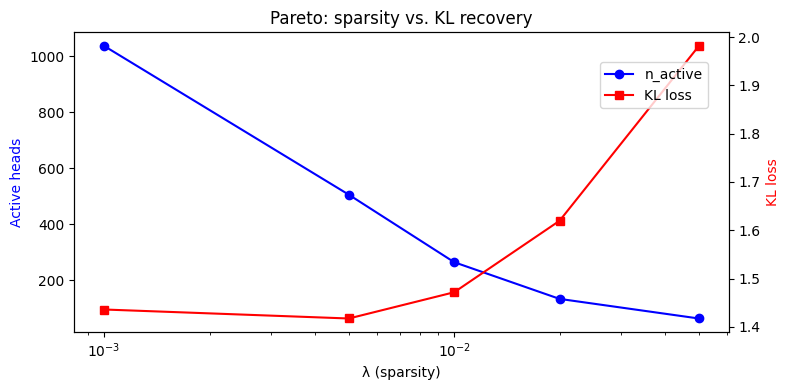

In [12]:
lambdas = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
pareto = []

for lam in lambdas:
    m, h = train_head_mask(mt, pivot_caches, layers=LAYERS, n_epochs=20, lr=1e-2, lambda_sparse=lam)
    pareto.append((lam, m.n_active(), h.loss_causal[-1]))
    print(f"  λ={lam:.0e}: n_active={m.n_active():4d}  KL={h.loss_causal[-1]:.4f}")

lams, n_acts, kls = zip(*pareto)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.semilogx(lams, n_acts, "b-o", label="n_active")
ax2.semilogx(lams, kls, "r-s", label="KL loss")
ax1.set_xlabel("λ (sparsity)")
ax1.set_ylabel("Active heads", color="b")
ax2.set_ylabel("KL loss", color="r")
ax1.set_title("Pareto: sparsity vs. KL recovery")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()
plt.show()

## Qualitative Evaluation

In [22]:

from src.goals.head_loc_attn import HeadMask, forward_with_masked_patch
from src.tokens import prepare_input

MAX_NEW_TOKENS = 32

# Stop at newline (end of `return <expr>` line) or EOS
_nl_ids = mt.tokenizer.encode("\n", add_special_tokens=False)
STOP_IDS = {mt.tokenizer.eos_token_id} | set(_nl_ids)


def greedy_generate_baseline(mt, input_ids, attention_mask, max_new_tokens=MAX_NEW_TOKENS):
    """Plain greedy generation — no patch."""
    input_ids = input_ids.clone()
    attention_mask = attention_mask.clone()
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            out = mt._model(input_ids=input_ids, attention_mask=attention_mask)
            next_tok = int(out.logits[0, -1, :].argmax())
            generated.append(next_tok)
            if next_tok in STOP_IDS:
                break
            next_tok_t = torch.tensor([[next_tok]], device=input_ids.device)
            ones = torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)
            input_ids = torch.cat([input_ids, next_tok_t], dim=1)
            attention_mask = torch.cat([attention_mask, ones], dim=1)
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def patched_generate(mt, pivot_cache, mask, layers, max_new_tokens=MAX_NEW_TOKENS, threshold=0.5):
    """Greedy generation with binary-thresholded head patch applied at every step.

    At each step the same per_head_deltas (precomputed at the original pivot position)
    are applied to the current last-token attention output — an approximation that is
    cheap and sufficient for a qualitative check.
    """
    binary_mask = HeadMask(mask.values.shape[0], mask.values.shape[1])
    with torch.no_grad():
        binary_mask.values.copy_((mask.values.detach() > threshold).float())

    input_ids = pivot_cache.dest_inputs["input_ids"].clone()
    attention_mask = pivot_cache.dest_inputs["attention_mask"].clone()

    generated = []
    for _ in range(max_new_tokens):
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
        with torch.no_grad():
            logits = forward_with_masked_patch(
                mt, inputs, pivot_cache.per_head_deltas, binary_mask, layers
            )
        next_tok = int(logits.argmax())
        generated.append(next_tok)
        if next_tok in STOP_IDS:
            break
        next_tok_t = torch.tensor([[next_tok]], device=input_ids.device)
        ones = torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)
        input_ids = torch.cat([input_ids, next_tok_t], dim=1)
        attention_mask = torch.cat([attention_mask, ones], dim=1)

    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def _first_word(s):
    parts = s.split()
    return parts[0] if parts else "?"


# ── Evaluation loop ──────────────────────────────────────────────────────────
print(f"Binary mask threshold=0.5 → {mask.n_active()} active heads\n")
print("=" * 80)

n_match = 0
for i, (cache, pi) in enumerate(zip(pivot_caches, pivot_instances)):
    targ_sample = ds.get_sample(pi.target_predicate)
    if pi.target_predicate != "is_palindrome":
        continue
    targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix)
    targ_inputs = prepare_input(prompts=[targ_prompt], tokenizer=mt)

    dest_baseline = greedy_generate_baseline(
        mt, cache.dest_inputs["input_ids"], cache.dest_inputs["attention_mask"]
    )
    targ_baseline = greedy_generate_baseline(
        mt, targ_inputs["input_ids"], targ_inputs["attention_mask"]
    )
    dest_patched = patched_generate(mt, cache, mask, layers=LAYERS)

    ret_prefix = f"return {pi.pivot_prefix}" if pi.pivot_prefix else "return"
    patched_w0 = _first_word(dest_patched)
    target_w0  = _first_word(targ_baseline)
    hit = patched_w0 == target_w0
    n_match += int(hit)
    marker = "✓" if hit else "✗"

    print(f"[{i+1:02d}] {pi.destination_predicate} ← {pi.source_predicate}  (prefix={pi.pivot_prefix!r})")
    print(f"  dest baseline : {ret_prefix} {dest_baseline}")
    print(f"  dest patched  : {ret_prefix} {dest_patched}")
    print(f"  target        : {ret_prefix} {targ_baseline}")
    print(f"  first-token   : {marker}  patched={patched_w0!r}  target={target_w0!r}")
    print()

print(f"First-token match: {n_match}/{len(pivot_caches)}")


Binary mask threshold=0.5 → 102 active heads

[05] is_upper ← is_palindrome  (prefix='')
  dest baseline : return 0 < len(s) and all(c.isupper() for c in s)
</code>

This function `is_upper` checks if a given string `s
  dest patched  : return 1
  target        : return  s == s[::-1]
</code>

This function `is_palindrome` takes a string `s` as input and returns `True` if the string
  first-token   : ✗  patched='1'  target='s'

[09] is_upper ← is_palindrome  (prefix=' s')
  dest baseline : return  s .isupper()
</code>

This function `is_upper` takes a string `s` as input and returns `True` if all the alphabetic characters in
  dest patched  : return  s  == s.upper()
</code>

This function `is_upper` takes a string `s` as input and returns `True` if the string is the same
  target        : return  s  == s[::-1]
</code>

This function `is_palindrome` takes a string `s` as input and returns `True` if the string is
  first-token   : ✓  patched='=='  target='=='

First-token match: 1/10
